# Experiment 004: 3B base-to-GRPO three-seed analysis

All three completed 004 base-start GRPO runs and
compares each seed with the matching 003 GSM8K-SFT-to-GRPO run. Seed 1
completes the registered second 3B base-GRPO seed and seed 2 is the
additional exploratory robustness arm.

Generative exact match is primary. The letter-probability probe remains a
diagnostic reference. Tiers are rebuilt from the current subject mapping
before any cross-era comparison. The notebook reads saved artifacts only
and does not need a GPU. Figures are saved to `analysis/figures/004_3/`.

In [1]:
# find the repo root and load the three matched route pairs
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
while not (ROOT / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from analysis.plotting import heatmap_text_color
from analysis.stats import align_pred_rows, holm, mcnemar_exact, paired_delta_ci
from data.subjects import tier_of

RES = ROOT / "results"
FIG = ROOT / "analysis" / "figures" / "004_3"
FIG.mkdir(parents=True, exist_ok=True)

SEEDS = (0, 1, 2)
TIERS = ("easy", "medium", "hard")
COLORS = {0: "#4C78A8", 1: "#F58518", 2: "#54A24B"}
ROUTE_COLORS = {"base to GRPO": "#4C78A8", "SFT to GRPO": "#E45756"}

def jload(path):
    with open(path) as handle:
        return json.load(handle)

def jsonl(path):
    with open(path) as handle:
        return [json.loads(line) for line in handle if line.strip()]

def retier(rows):
    # rebuild tiers from the current subject mapping
    rebuilt = []
    for row in rows:
        row = dict(row)
        row["tier"] = tier_of(row["subject"])
        rebuilt.append(row)
    return rebuilt

def overall(rows):
    return float(np.mean([row["correct"] for row in rows]))

def grouped_accuracy(rows, field, value):
    selected = [row["correct"] for row in rows if row[field] == value]
    return float(np.mean(selected))

def load_run(path):
    return {
        "preds": retier(jsonl(path / "grpo_preds.jsonl")),
        "probe": retier(jsonl(path / "grpo_logprob_preds.jsonl")),
        "train": jload(path / "grpo_trainlog.json"),
        "eval": jload(path / "grpo_eval.json"),
        "probe_eval": jload(path / "grpo_logprob.json"),
        "manifest": jload(path / "manifest.json"),
    }

def metric_series(rows, key):
    selected = [row for row in rows if key in row and "step" in row]
    return (
        np.array([row["step"] for row in selected]),
        np.array([row[key] for row in selected], dtype=float),
    )

def smooth(values, window=15):
    # use a rolling mean because rollout metrics are noisy
    if len(values) < window:
        return values
    return np.convolve(values, np.ones(window) / window, mode="valid")

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight")
    print("saved", name)

BASE = {
    seed: load_run(RES / f"004_COLAB_FULL_B3_base_grpo_seed{seed}")
    for seed in SEEDS
}
WARM = {
    seed: load_run(RES / f"003_COLAB_FULL_B3_sft_grpo_seed{seed}")
    for seed in SEEDS
}
RAW_PROBE = retier(jsonl(RES / "base_evals" / "004_COLAB_FULL_B3" / "base_logprob_preds.jsonl"))

for seed in SEEDS:
    reward_steps = [row["step"] for row in BASE[seed]["train"] if "reward" in row]
    assert reward_steps == list(range(1, 501)), f"seed {seed}: incomplete training history"
    for route in (BASE, WARM):
        assert len(route[seed]["preds"]) == 1884
        assert len(route[seed]["probe"]) == 1884
        assert route[seed]["manifest"]["seed"] == seed
    left, right = align_pred_rows(BASE[seed]["preds"], WARM[seed]["preds"])
    assert len(left) == len(right) == 1884
    assert "A100" in BASE[seed]["manifest"]["gpu"]["device"]
    if seed in (1, 2):
        assert BASE[seed]["manifest"]["config"]["exec"]["allow_oom_fallback"] is False

assert len(RAW_PROBE) == 1884
print("loaded three complete 004 runs and three matched 003 runs")

loaded three complete 004 runs and three matched 003 runs


## 1. Run health and completion

Completion checks stay separate from the accuracy results.

In [2]:
# summarise completion, environment and memory for all three base-route seeds
health_rows = []
for seed, data in BASE.items():
    manifest = data["manifest"]
    timings = manifest["timings_sec"]
    reward_rows = [row for row in data["train"] if "reward" in row]
    health_rows.append({
        "seed": seed,
        "status": "confirmatory" if seed == 1 else ("exploratory" if seed == 2 else "original"),
        "steps": len(reward_rows),
        "gen_rows": len(data["preds"]),
        "probe_rows": len(data["probe"]),
        "dtype": manifest.get("resolved_dtype") or "auto (legacy)",
        "gpu": manifest["gpu"]["device"],
        "peak_vram_gb": manifest["gpu"]["peak_vram_gb"],
        "train_hours": timings["grpo_train"] / 3600,
        "gen_eval_hours": timings["grpo_eval"] / 3600,
    })
health_tbl = pd.DataFrame(health_rows).set_index("seed")
display(health_tbl.round(3))

,status,steps,gen_rows,probe_rows,dtype,gpu,peak_vram_gb,train_hours,gen_eval_hours
seed,,,,,,,,,
0,original,500,1884,1884,auto (legacy),NVIDIA A100-SXM4-80GB,52.083,4.335,1.281
1,confirmatory,500,1884,1884,bfloat16,NVIDIA A100-SXM4-80GB,52.083,3.543,1.214
2,exploratory,500,1884,1884,bfloat16,NVIDIA A100-SXM4-80GB,51.639,4.745,1.215


## 2. GRPO training behaviour

The same reward and rollout diagnostics are shown for each seed. The format
reward is divided by its 0.2 weight so it reads as rollout compliance.

saved fig01_training_rewards


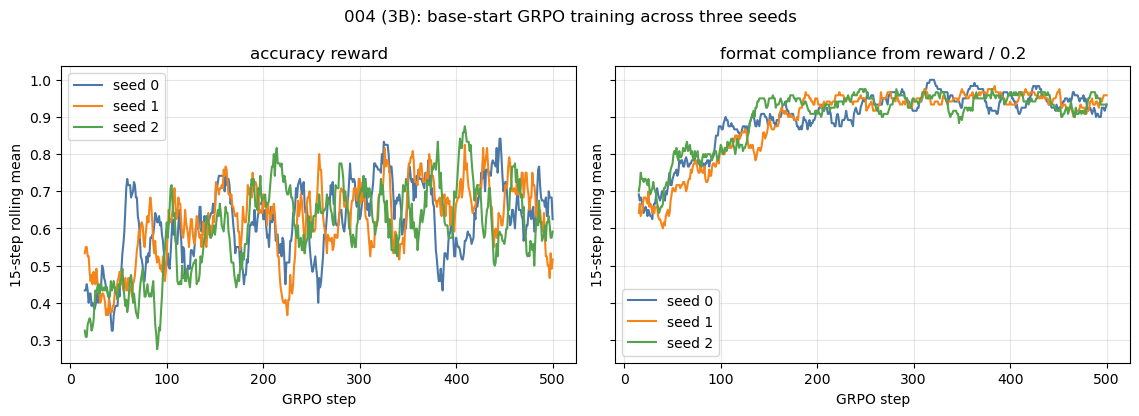

In [3]:
# compare accuracy and format reward across all 500 GRPO steps
window = 15
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=True)
for seed, data in BASE.items():
    steps, accuracy_reward = metric_series(data["train"], "rewards/accuracy_reward/mean")
    _, format_reward = metric_series(data["train"], "rewards/format_reward/mean")
    axes[0].plot(steps[window - 1:], smooth(accuracy_reward, window), color=COLORS[seed], label=f"seed {seed}")
    axes[1].plot(steps[window - 1:], smooth(format_reward, window) / 0.2, color=COLORS[seed], label=f"seed {seed}")
axes[0].set_title("accuracy reward")
axes[1].set_title("format compliance from reward / 0.2")
for ax in axes:
    ax.set_xlabel("GRPO step")
    ax.set_ylabel("15-step rolling mean")
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle("004 (3B): base-start GRPO training across three seeds")
fig.tight_layout()
save(fig, "fig01_training_rewards")
plt.show()

saved fig02_training_diagnostics


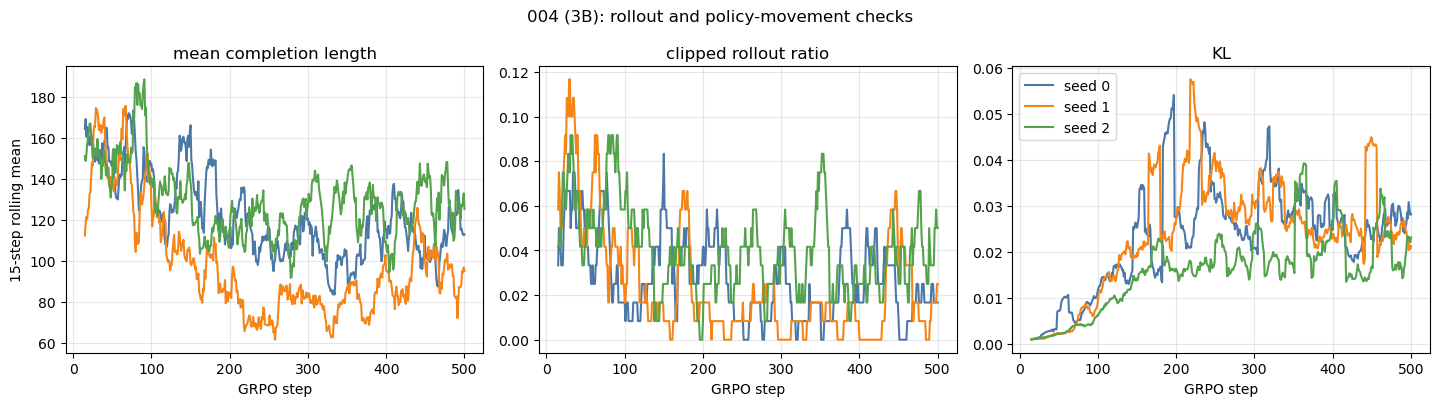

In [4]:
# compare rollout length, clipping and kl without hiding seed variation
panels = [
    ("completions/mean_length", "mean completion length", 1.0),
    ("completions/clipped_ratio", "clipped rollout ratio", 1.0),
    ("kl", "KL", 1.0),
]
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.1))
for ax, (key, title, divisor) in zip(axes, panels):
    for seed, data in BASE.items():
        steps, values = metric_series(data["train"], key)
        ax.plot(steps[window - 1:], smooth(values / divisor, window), color=COLORS[seed], label=f"seed {seed}")
    ax.set_title(title)
    ax.set_xlabel("GRPO step")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("15-step rolling mean")
axes[-1].legend()
fig.suptitle("004 (3B): rollout and policy-movement checks")
fig.tight_layout()
save(fig, "fig02_training_diagnostics")
plt.show()

## 3. Three-seed base-to-GRPO endpoint

The bars show the three-seed mean and full range. Individual dots remain
visible, and the raw-base letter probe is drawn as a diagnostic reference.

saved fig03_base_route_endpoint


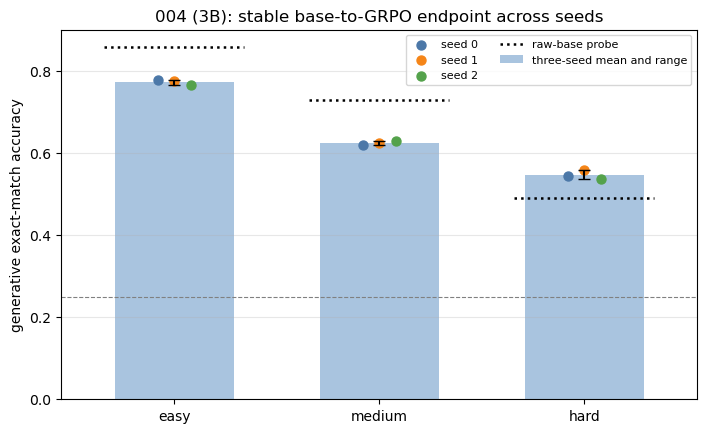

In [5]:
# show the three base-route endpoints by tier against the shared raw-base probe
tier_values = np.array([
    [grouped_accuracy(BASE[seed]["preds"], "tier", tier) for tier in TIERS]
    for seed in SEEDS
])
probe_values = np.array([grouped_accuracy(RAW_PROBE, "tier", tier) for tier in TIERS])
means = tier_values.mean(axis=0)
errors = np.vstack([means - tier_values.min(axis=0), tier_values.max(axis=0) - means])

fig, ax = plt.subplots(figsize=(8.2, 4.8))
xpos = np.arange(len(TIERS))
ax.bar(xpos, means, width=0.58, yerr=errors, capsize=4, color="#A9C4DF", label="three-seed mean and range")
for index, seed in enumerate(SEEDS):
    ax.scatter(xpos + (index - 1) * 0.08, tier_values[index], s=42, color=COLORS[seed], label=f"seed {seed}")
for index, value in enumerate(probe_values):
    ax.hlines(value, index - 0.34, index + 0.34, color="black", ls=":", lw=1.8)
ax.hlines(0, 10, 11, color="black", ls=":", lw=1.8, label="raw-base probe")
ax.axhline(0.25, color="grey", ls="--", lw=0.8)
ax.set_xlim(-0.55, 2.55)
ax.set_xticks(xpos)
ax.set_xticklabels(TIERS)
ax.set_ylabel("generative exact-match accuracy")
ax.set_title("004 (3B): stable base-to-GRPO endpoint across seeds")
ax.grid(alpha=0.3, axis="y")
ax.legend(fontsize=8, ncol=2)
save(fig, "fig03_base_route_endpoint")
plt.show()

## 4. Matched warm-start comparison

Each comparison uses the same seed and the same 1,884 MMLU items. Positive
deltas mean the GSM8K SFT warm start produced the stronger GRPO endpoint.
Holm correction is applied across the three overall seed comparisons.

saved fig04_matched_route_endpoints


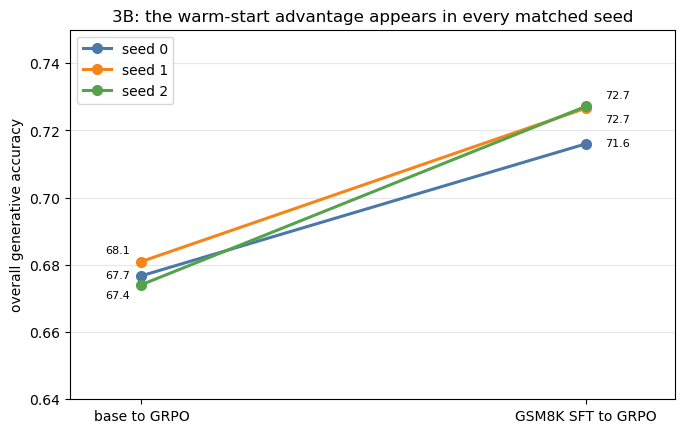

,base_grpo,warm_grpo,warm_minus_base,ci_low,ci_high,mcnemar_p,base_only,warm_only,holm_p,reading
seed,,,,,,,,,,
0,0.67675,0.71603,0.03928,0.01963,0.05892,0.00017,152,226,0.00017,material warm advantage
1,0.68100,0.72665,0.04565,0.02601,0.06582,0.00001,147,233,0.00002,material warm advantage
2,0.67410,0.72718,0.05308,0.03291,0.07325,0.00000,146,246,0.00000,material warm advantage


In [6]:
# calculate the registered matched-seed route comparison
route_rows = []
raw_p = []
for seed in SEEDS:
    base_rows, warm_rows = align_pred_rows(BASE[seed]["preds"], WARM[seed]["preds"])
    base_correct = [row["correct"] for row in base_rows]
    warm_correct = [row["correct"] for row in warm_rows]
    delta, low, high = paired_delta_ci(base_correct, warm_correct, seed=400 + seed)
    base_only = sum(a and not b for a, b in zip(base_correct, warm_correct))
    warm_only = sum((not a) and b for a, b in zip(base_correct, warm_correct))
    p_value = mcnemar_exact(warm_only, base_only)
    raw_p.append(p_value)
    route_rows.append({
        "seed": seed,
        "base_grpo": np.mean(base_correct),
        "warm_grpo": np.mean(warm_correct),
        "warm_minus_base": delta,
        "ci_low": low,
        "ci_high": high,
        "mcnemar_p": p_value,
        "base_only": base_only,
        "warm_only": warm_only,
    })
adjusted = holm(raw_p)
for row, adjusted_p in zip(route_rows, adjusted):
    row["holm_p"] = adjusted_p
    if abs(row["warm_minus_base"]) >= 0.02 and adjusted_p < 0.05:
        row["reading"] = "material warm advantage" if row["warm_minus_base"] > 0 else "material base advantage"
    elif row["ci_low"] >= -0.02 and row["ci_high"] <= 0.02:
        row["reading"] = "equivalent"
    else:
        row["reading"] = "inconclusive"
route_tbl = pd.DataFrame(route_rows).set_index("seed")

fig, ax = plt.subplots(figsize=(7.8, 4.8))
for seed, row in route_tbl.iterrows():
    values = [row["base_grpo"], row["warm_grpo"]]
    ax.plot([0, 1], values, "o-", lw=2.2, ms=7, color=COLORS[seed], label=f"seed {seed}")
    left_offset = {0: 0, 1: 8, 2: -8}[seed]
    right_offset = {0: 0, 1: -8, 2: 8}[seed]
    ax.annotate(f"{100 * values[0]:.1f}", (0, values[0]), xytext=(-8, left_offset), textcoords="offset points", ha="right", va="center", fontsize=8)
    ax.annotate(f"{100 * values[1]:.1f}", (1, values[1]), xytext=(14, right_offset), textcoords="offset points", ha="left", va="center", fontsize=8)
ax.set_xlim(-0.16, 1.2)
ax.set_xticks([0, 1])
ax.set_xticklabels(["base to GRPO", "GSM8K SFT to GRPO"])
ax.set_ylabel("overall generative accuracy")
ax.set_ylim(0.64, 0.75)
ax.set_title("3B: the warm-start advantage appears in every matched seed")
ax.grid(alpha=0.3, axis="y")
ax.legend()
save(fig, "fig04_matched_route_endpoints")
plt.show()

display(route_tbl.round(5))

saved fig05_route_delta_by_tier


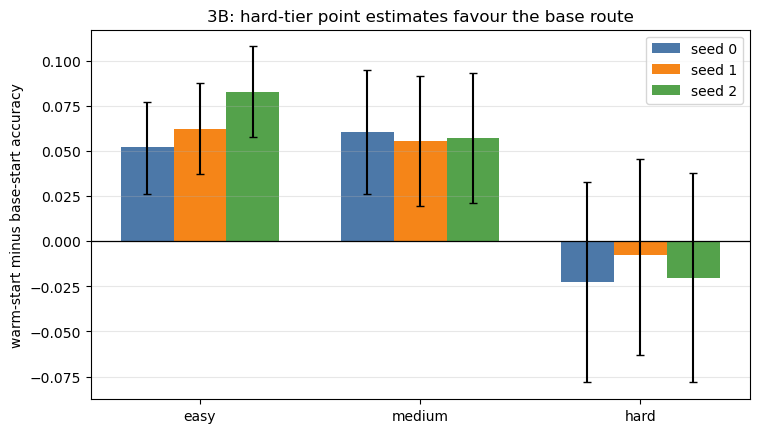

delta  ci_low  ci_high
seed tier                           
0    easy    0.0523  0.0262   0.0774
     medium  0.0608  0.0263   0.0952
     hard   -0.0227 -0.0783   0.0328
1    easy    0.0626  0.0375   0.0876
     medium  0.0558  0.0197   0.0920
     hard   -0.0076 -0.0631   0.0455
2    easy    0.0830  0.0580   0.1081
     medium  0.0575  0.0213   0.0936
     hard   -0.0202 -0.0783   0.0379

In [7]:
# split the matched route difference by tier for every seed
tier_rows = []
for seed in SEEDS:
    base_rows, warm_rows = align_pred_rows(BASE[seed]["preds"], WARM[seed]["preds"])
    for tier in TIERS:
        pairs = [(a["correct"], b["correct"]) for a, b in zip(base_rows, warm_rows) if a["tier"] == tier]
        base_correct = [a for a, _ in pairs]
        warm_correct = [b for _, b in pairs]
        delta, low, high = paired_delta_ci(base_correct, warm_correct, seed=500 + 10 * seed + TIERS.index(tier))
        tier_rows.append({"seed": seed, "tier": tier, "delta": delta, "ci_low": low, "ci_high": high})
tier_tbl = pd.DataFrame(tier_rows)

fig, ax = plt.subplots(figsize=(8.5, 4.8))
xpos = np.arange(len(TIERS))
width = 0.24
for index, seed in enumerate(SEEDS):
    selected = tier_tbl[tier_tbl["seed"] == seed].set_index("tier").loc[list(TIERS)]
    values = selected["delta"].to_numpy()
    errors = np.vstack([values - selected["ci_low"].to_numpy(), selected["ci_high"].to_numpy() - values])
    positions = xpos + (index - 1) * width
    ax.bar(positions, values, width, yerr=errors, capsize=3, color=COLORS[seed], label=f"seed {seed}")
ax.axhline(0, color="black", lw=0.9)
ax.set_xticks(xpos)
ax.set_xticklabels(TIERS)
ax.set_ylabel("warm-start minus base-start accuracy")
ax.set_title("3B: hard-tier point estimates favour the base route")
ax.grid(alpha=0.3, axis="y")
ax.legend()
save(fig, "fig05_route_delta_by_tier")
plt.show()

display(tier_tbl.set_index(["seed", "tier"]).round(4))

## 5. Format, response length and the knowledge probe

These diagnostics separate improved answer expression from changes in the
underlying letter preference. The raw-base probe is shared across 004 seeds.

saved fig06_route_diagnostics


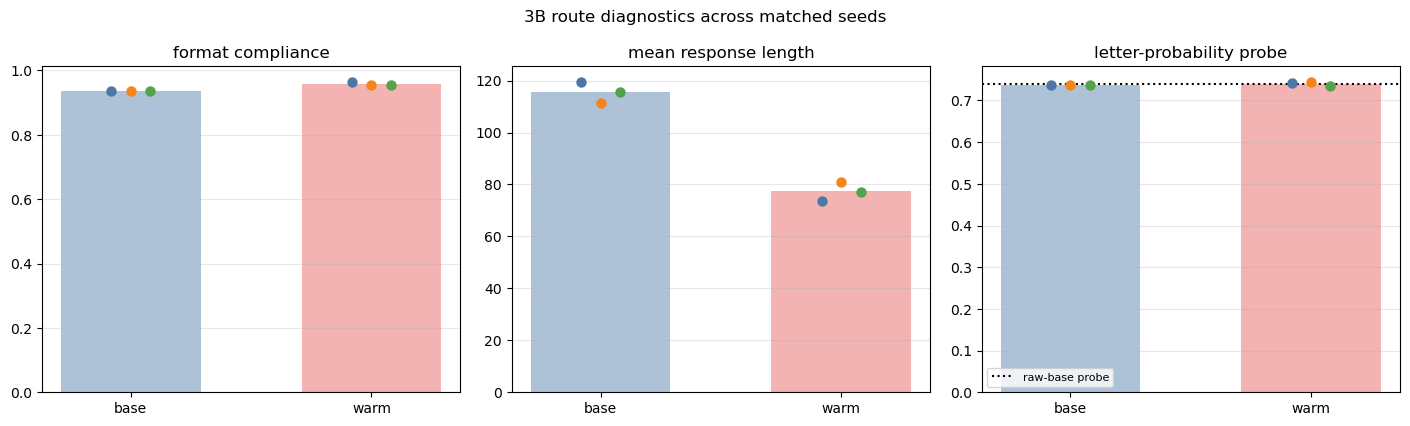

format  mean_length  probe_accuracy  gen_accuracy
route        seed                                                   
base to GRPO 0     0.9374     119.5042          0.7373        0.6768
             1     0.9347     111.1975          0.7378        0.6810
             2     0.9358     115.7818          0.7383        0.6741
SFT to GRPO  0     0.9644      73.7001          0.7410        0.7160
             1     0.9544      81.0626          0.7447        0.7266
             2     0.9533      77.2712          0.7351        0.7272

In [8]:
# compare route diagnostics while keeping all three seeds visible
diagnostic_rows = []
for label, runs in (("base to GRPO", BASE), ("SFT to GRPO", WARM)):
    for seed, data in runs.items():
        diagnostic_rows.append({
            "route": label,
            "seed": seed,
            "format": float(np.mean([row["format_ok"] for row in data["preds"]])),
            "mean_length": float(np.mean([row["n_tokens"] for row in data["preds"]])),
            "probe_accuracy": overall(data["probe"]),
            "gen_accuracy": overall(data["preds"]),
        })
diagnostic_tbl = pd.DataFrame(diagnostic_rows)

panels = [("format", "format compliance"), ("mean_length", "mean response length"), ("probe_accuracy", "letter-probability probe")]
fig, axes = plt.subplots(1, 3, figsize=(14.2, 4.3))
for ax, (metric, title) in zip(axes, panels):
    for x, route in enumerate(("base to GRPO", "SFT to GRPO")):
        values = diagnostic_tbl.loc[diagnostic_tbl["route"] == route, metric].to_numpy()
        ax.bar(x, values.mean(), width=0.58, color=ROUTE_COLORS[route], alpha=0.45)
        for index, value in enumerate(values):
            ax.scatter(x + (index - 1) * 0.08, value, color=COLORS[index], s=42, zorder=3)
    if metric == "probe_accuracy":
        ax.axhline(overall(RAW_PROBE), color="black", ls=":", lw=1.5, label="raw-base probe")
        ax.legend(fontsize=8)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["base", "warm"])
    ax.set_title(title)
    ax.grid(alpha=0.3, axis="y")
fig.suptitle("3B route diagnostics across matched seeds")
fig.tight_layout()
save(fig, "fig06_route_diagnostics")
plt.show()

display(diagnostic_tbl.set_index(["route", "seed"]).round(4))

saved fig07_probe_movement


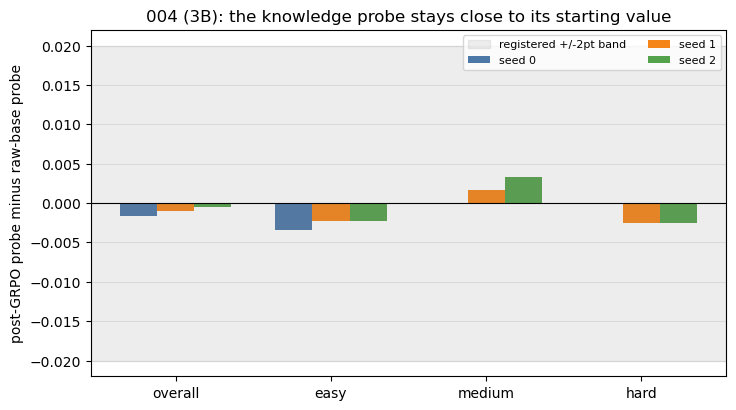

,overall,easy,medium,hard
seed,,,,
0,-0.0016,-0.0034,0.0000,0.0000
1,-0.0011,-0.0023,0.0016,-0.0025
2,-0.0005,-0.0023,0.0033,-0.0025


In [9]:
# measure base-route probe movement against the shared raw-base reference
raw_probe_by_tier = {tier: grouped_accuracy(RAW_PROBE, "tier", tier) for tier in TIERS}
raw_probe_overall = overall(RAW_PROBE)
probe_rows = []
for seed, data in BASE.items():
    row = {"seed": seed, "overall": overall(data["probe"]) - raw_probe_overall}
    for tier in TIERS:
        row[tier] = grouped_accuracy(data["probe"], "tier", tier) - raw_probe_by_tier[tier]
    probe_rows.append(row)
probe_tbl = pd.DataFrame(probe_rows).set_index("seed")

fig, ax = plt.subplots(figsize=(8.2, 4.5))
labels = ["overall", *TIERS]
xpos = np.arange(len(labels))
width = 0.24
for index, seed in enumerate(SEEDS):
    values = probe_tbl.loc[seed, labels].to_numpy(dtype=float)
    ax.bar(xpos + (index - 1) * width, values, width, color=COLORS[seed], label=f"seed {seed}")
ax.axhspan(-0.02, 0.02, color="grey", alpha=0.14, label="registered +/-2pt band")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(xpos)
ax.set_xticklabels(labels)
ax.set_ylabel("post-GRPO probe minus raw-base probe")
ax.set_title("004 (3B): the knowledge probe stays close to its starting value")
ax.grid(alpha=0.3, axis="y")
ax.legend(fontsize=8, ncol=2)
save(fig, "fig07_probe_movement")
plt.show()

display(probe_tbl.round(4))

saved fig08_subject_route_matrix


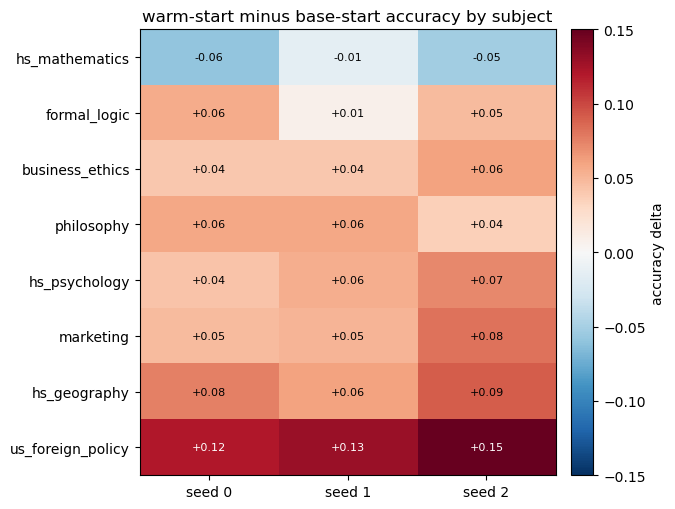

,seed_0,seed_1,seed_2
business_ethics,0.0400,0.0400,0.0600
formal_logic,0.0556,0.0079,0.0476
high_school_geography,0.0758,0.0606,0.0909
high_school_mathematics,-0.0593,-0.0148,-0.0519
high_school_psychology,0.0422,0.0550,0.0716
marketing,0.0470,0.0513,0.0812
philosophy,0.0579,0.0579,0.0354
us_foreign_policy,0.1200,0.1300,0.1500


In [10]:
# show where the matched route difference agrees or changes across subjects
subjects = sorted({row["subject"] for row in BASE[0]["preds"]})
subject_values = np.zeros((len(subjects), len(SEEDS)))
for column, seed in enumerate(SEEDS):
    base_rows, warm_rows = align_pred_rows(BASE[seed]["preds"], WARM[seed]["preds"])
    for row_index, subject in enumerate(subjects):
        base_acc = grouped_accuracy(base_rows, "subject", subject)
        warm_acc = grouped_accuracy(warm_rows, "subject", subject)
        subject_values[row_index, column] = warm_acc - base_acc
order = np.argsort(subject_values.mean(axis=1))
ordered = subject_values[order]
labels = [subjects[index].replace("high_school_", "hs_") for index in order]
limit = max(abs(ordered.min()), abs(ordered.max()))

fig, ax = plt.subplots(figsize=(6.8, 5.2))
image = ax.imshow(ordered, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto", interpolation="nearest")
for row_index in range(ordered.shape[0]):
    for column in range(ordered.shape[1]):
        color = heatmap_text_color(image, ordered[row_index, column])
        ax.text(column, row_index, f"{ordered[row_index, column]:+.2f}", ha="center", va="center", fontsize=8, color=color)
ax.set_xticks(range(len(SEEDS)))
ax.set_xticklabels([f"seed {seed}" for seed in SEEDS])
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels)
ax.set_title("warm-start minus base-start accuracy by subject")
colorbar = fig.colorbar(image, ax=ax, pad=0.03)
colorbar.set_label("accuracy delta")
fig.tight_layout()
save(fig, "fig08_subject_route_matrix")
plt.show()

subject_tbl = pd.DataFrame(subject_values, index=subjects, columns=[f"seed_{seed}" for seed in SEEDS])
display(subject_tbl.round(4))

## 6. Compute and exact endpoint tables

The shared base evaluation is excluded here because seeds 1 and 2 reused it.
The bars therefore show the comparable work performed inside each 004 arm.

saved fig09_compute_by_seed


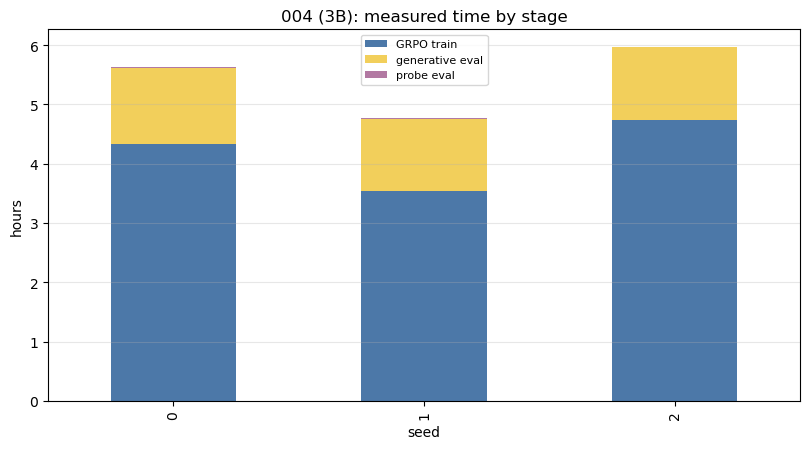

,GRPO train,generative eval,probe eval
seed,,,
0,4.335,1.281,0.008
1,3.543,1.214,0.007
2,4.745,1.215,0.007


In [11]:
# compare measured GRPO training and evaluation time across seeds
compute_rows = []
for seed, data in BASE.items():
    timings = data["manifest"]["timings_sec"]
    compute_rows.append({
        "seed": seed,
        "GRPO train": timings["grpo_train"] / 3600,
        "generative eval": timings["grpo_eval"] / 3600,
        "probe eval": timings["grpo_logprob_eval"] / 3600,
    })
compute_tbl = pd.DataFrame(compute_rows).set_index("seed")
ax = compute_tbl.plot(kind="bar", stacked=True, figsize=(8.2, 4.6), color=["#4C78A8", "#F2CF5B", "#B279A2"])
ax.set_ylabel("hours")
ax.set_xlabel("seed")
ax.set_title("004 (3B): measured time by stage")
ax.grid(alpha=0.3, axis="y")
ax.legend(fontsize=8)
fig = ax.get_figure()
fig.tight_layout()
save(fig, "fig09_compute_by_seed")
plt.show()

display(compute_tbl.round(3))

In [12]:
# keep the exact endpoint values used by the figures in one table
endpoint_rows = []
for route, runs in (("base to GRPO", BASE), ("SFT to GRPO", WARM)):
    for seed, data in runs.items():
        row = {
            "route": route,
            "seed": seed,
            "overall": overall(data["preds"]),
            "format": float(np.mean([item["format_ok"] for item in data["preds"]])),
            "mean_length": float(np.mean([item["n_tokens"] for item in data["preds"]])),
            "probe_overall": overall(data["probe"]),
        }
        for tier in TIERS:
            row[tier] = grouped_accuracy(data["preds"], "tier", tier)
        endpoint_rows.append(row)
endpoint_tbl = pd.DataFrame(endpoint_rows).set_index(["route", "seed"])
display(endpoint_tbl.round(4))

overall  format  mean_length  probe_overall    easy  \
route        seed                                                        
base to GRPO 0      0.6768  0.9374     119.5042         0.7373  0.7770   
             1      0.6810  0.9347     111.1975         0.7378  0.7747   
             2      0.6741  0.9358     115.7818         0.7383  0.7668   
SFT to GRPO  0      0.7160  0.9644      73.7001         0.7410  0.8294   
             1      0.7266  0.9544      81.0626         0.7447  0.8373   
             2      0.7272  0.9533      77.2712         0.7351  0.8498   

                   medium    hard  
route        seed                  
base to GRPO 0     0.6190  0.5429  
             1     0.6256  0.5581  
             2     0.6289  0.5379  
SFT to GRPO  0     0.6798  0.5202  
             1     0.6814  0.5505  
             2     0.6864  0.5177

## Cross-referenced conclusion

All three 004 base-start runs completed normally on A100-80GB. Each has
exactly 500 GRPO steps and complete 1,884-item generative and probe
evaluations. No execution fallback was used in the new arms.

The 3B base-to-GRPO endpoint is very stable: overall accuracy is 67.7%,
68.1% and 67.4%, a range of only 0.7 points. Format compliance also stays
stable at about 93.5%. The seed-0 result was therefore not a lucky draw.

The GSM8K warm start improves the matched overall endpoint by 3.9, 4.6
and 5.3 points. All three differences are material under the registered
rule and remain significant after Holm correction. The effect is not the
same across tiers: the warm route gains 5.2 to 8.3 points on easy and
5.6 to 6.1 on medium. Hard-tier point estimates favour the base route by
0.8 to 2.3 points in every seed, but all three paired intervals cross zero,
so that secondary difference is not decisive. The overall warm-start
benefit at 3B is replicated and is concentrated in easy and medium.

The post-GRPO letter probe remains close to the shared raw-base probe in
every seed. This supports the existing elicitation interpretation.